<div style="text-align: center; margin-bottom: 20px;">
    <img src="logo/Logo_Facyt.svg.png" width="180" style="display: block; margin-left: auto; margin-right: auto; margin-bottom: 10px;">
    <h2 style="color: #1B365D; margin-bottom: 2px;">UNIVERSITY OF CARABOBO</h2>
    <h3 style="color: #2B5B84; margin-top: 0px;">EXPERIMENTAL FACULTY OF SCIENCE AND TECHNOLOGY (FACYT)</h3>
    <h4 style="color: #4A777A;">DEPARTMENT OF COMPUTER SCIENCE</h4>
    <p><strong>Course:</strong> Machine Learning (Elective 2026) | <strong>Professor:</strong> Álvaro Espinoza</p>
    <p><strong>Authors:</strong> Anthony Quero & Luigi Quero</p>
    <hr style="border: 1px solid #2B5B84; margin: 15px 0;">
    <h1 style="color: #D9534F; margin-bottom: 5px;">Assignment 3: Model Selection and Hyperparameter Optimization</h1>
    <h3 style="color: #333333;">Project: Pokémon Battle Winner Predictor</h3>
</div>

# 1. Objective, Metric and Evaluation Protocol

This notebook selects the final model of the project. It reuses the decisions of the EDA (`01_eda_pokemon.ipynb`) and the preparation pipeline of `02_data_preparation.ipynb`, and answers one question with cross-validated evidence: **which pipeline generalizes best to new battles between known Pokémon, and why is that choice defensible?**

| Element | Decision | Justification |
|---|---|---|
| **Task** | Binary classification: `Target_First_Wins` (1 = `First_pokemon` wins) | Unit of observation and target defined in the EDA. |
| **Primary metric** | **Accuracy** | The classes are close to balanced (47.2% / 52.8%) and a wrong winner costs the same in either direction, so the share of correctly predicted battles is the real error to minimize. It is also the metric of the Strong Speed-Based Baseline (94.05% in the EDA), which is the benchmark to beat. |
| **Secondary metrics** | ROC AUC, macro F1, confusion matrix and per-class report | ROC AUC checks how well the model ranks battles across thresholds; macro F1 and the per-class report show whether one class is systematically worse predicted. |
| **Split** | Train / test partition loaded from `artifacts/split_assignments_pokemon.csv` (40,078 / 9,922 battles, grouped by unordered pair) | Same partition as notebook 02, verified by hash below. |
| **Validation** | `StratifiedGroupKFold` with 5 folds on the training partition, grouped by `pair_group` | Several rows share the same matchup (duplicates and reversed orientations), so plain `StratifiedKFold` would put the same matchup in training and validation folds. Groups keep the *Scenario A* definition inside cross-validation; stratification keeps the class balance per fold. |
| **Test** | Used **once**, after every decision is closed | No model, arm, hyperparameter or threshold is chosen with test. |

**Decision rules fixed before looking at any result:**
1. *Representation arm:* for each arm, take its best initial model; among the arms whose best mean accuracy is within one standard error (std / √5) of the overall best, keep the one with the fewest output columns.
2. *Tuning candidates:* the two models with the highest mean CV accuracy on the selected arm.
3. *Final pipeline:* among all initial and tuned configurations on the selected arm, the configurations within one standard error of the best mean accuracy are considered equivalent, and the one with the lowest cross-validation wall time is selected.

> **Test-set caveat (as in notebook 02):** the EDA explored all 50,000 battles, including the battles that now form the holdout, so the test partition is not a fully untouched external sample. In this notebook it is used exactly once.

# 2. Setup and Recovery of the Notebook 02 Pipeline

The modeling notebook must not depend on variables created in another notebook. We import the shared code instead of copying it: `create_pokemon_features` from `scripts/features.py`, and the representation arms (`FEATURE_SETS`), the pipeline factory (`build_model_pipeline`) and the speed rule (`speed_rule_predict`) from `scripts/preprocessing.py`. Every pipeline goes from the raw pair of IDs to the prediction, so feature engineering, scaling and encoding are refitted inside each fold.

In [1]:
from __future__ import annotations

import hashlib
import json
import sys
import time
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import optuna
import pandas as pd
import sklearn
from sklearn.dummy import DummyClassifier
from sklearn.ensemble import HistGradientBoostingClassifier, RandomForestClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    ConfusionMatrixDisplay, accuracy_score, classification_report, f1_score, roc_auc_score,
)
from sklearn.model_selection import StratifiedGroupKFold, cross_validate
from sklearn.neighbors import KNeighborsClassifier

RANDOM_STATE = 42
N_SPLITS = 5
SCORING = {"accuracy": "accuracy", "roc_auc": "roc_auc", "f1_macro": "f1_macro"}

# Resolve project paths from the repository root or from notebooks/
PROJECT_ROOT = Path.cwd()
if not (PROJECT_ROOT / "data" / "pokemon.csv").exists():
    PROJECT_ROOT = PROJECT_ROOT.parent
DATA_DIR = PROJECT_ROOT / "data"
SCRIPTS_DIR = PROJECT_ROOT / "scripts"
ARTIFACTS_DIR = PROJECT_ROOT / "artifacts"
if str(SCRIPTS_DIR) not in sys.path:
    sys.path.insert(0, str(SCRIPTS_DIR))

from features import create_pokemon_features
from preprocessing import FEATURE_SETS, build_model_pipeline, speed_rule_predict

# Optuna logs one line per trial; the full trial history is shown as a table instead
optuna.logging.set_verbosity(optuna.logging.WARNING)

validation_log: list[dict[str, str]] = []


def check(condition: bool, name: str, detail: str) -> None:
    """Validate an invariant: record on success, raise informative ValueError on failure."""
    if not bool(condition):
        raise ValueError(f"Validation FAILED — {name}: {detail}")
    validation_log.append({"Check": name, "Detail": detail, "Status": "PASSED ✓"})


print(f"scikit-learn {sklearn.__version__} | optuna {optuna.__version__} | pandas {pd.__version__} | numpy {np.__version__}")

scikit-learn 1.9.0 | optuna 5.0.0 | pandas 3.0.5 | numpy 2.5.2


### 2.1 Load the data and the split manifest

We read the raw files, verify that data and shared code are byte-identical (LF-normalized SHA-256) to those used by notebook 02, and rebuild `X_train`, `y_train`, the pair groups and `X_test`, `y_test` from the manifest. The holdout labels are not summarized here.

In [2]:
pokemon = pd.read_csv(DATA_DIR / "pokemon.csv")
combats = pd.read_csv(DATA_DIR / "combats.csv")
manifest = pd.read_csv(ARTIFACTS_DIR / "split_assignments_pokemon.csv", index_col="combat_id")
metadata = json.loads((ARTIFACTS_DIR / "feature_engineering_metadata.json").read_text(encoding="utf-8"))


def file_sha256(path: Path) -> str:
    # Line endings normalized to LF, as in notebook 02
    return hashlib.sha256(path.read_bytes().replace(b"\r\n", b"\n")).hexdigest()


for rel_path, expected in metadata["sha256"].items():
    check(file_sha256(PROJECT_ROOT / rel_path) == expected, f"Unchanged since notebook 02: {rel_path}", "SHA-256 matches")

check(manifest.index.equals(combats.index), "Manifest aligned with combats.csv", f"{len(manifest):,} rows, same combat_id order")
check((manifest[["First_pokemon", "Second_pokemon"]].to_numpy() == combats[["First_pokemon", "Second_pokemon"]].to_numpy()).all(),
      "Manifest IDs", "Fighter IDs identical to combats.csv")

# Deterministic catalogue fix of notebook 02 (§5): species #63 is Primeape
pokemon.loc[pokemon["#"] == 63, "Name"] = "Primeape"

y = (combats["Winner"] == combats["First_pokemon"]).astype(int).rename("Target_First_Wins")
X = combats[["First_pokemon", "Second_pokemon"]]
is_train = manifest["split"].eq("train")

X_train, y_train = X[is_train], y[is_train]
groups_train = manifest.loc[is_train, "pair_group"]
X_test, y_test = X[~is_train], y[~is_train]

check(len(X_train) == metadata["n_train"] and len(X_test) == metadata["n_test"], "Partition sizes",
      f"{len(X_train):,} train / {len(X_test):,} test (as recorded by notebook 02)")
check(set(groups_train).isdisjoint(manifest.loc[~is_train, "pair_group"]), "Holdout isolation", "No pair group in both partitions")
pd.DataFrame(validation_log)

,Check,Detail,Status
0,Unchanged since notebook 02: data/pokemon.csv,SHA-256 matches,PASSED ✓
1,Unchanged since notebook 02: data/combats.csv,SHA-256 matches,PASSED ✓
2,Unchanged since notebook 02: data/tests.csv,SHA-256 matches,PASSED ✓
3,Unchanged since notebook 02: scripts/features.py,SHA-256 matches,PASSED ✓
4,Unchanged since notebook 02: scripts/preproces...,SHA-256 matches,PASSED ✓
5,Manifest aligned with combats.csv,"50,000 rows, same combat_id order",PASSED ✓
6,Manifest IDs,Fighter IDs identical to combats.csv,PASSED ✓
7,Partition sizes,"40,078 train / 9,922 test (as recorded by note...",PASSED ✓
8,Holdout isolation,No pair group in both partitions,PASSED ✓


**Interpretation.** All nine checks pass: the data files and both shared modules are identical to those used by notebook 02, the manifest matches `combats.csv` row by row, and the 40,078 / 9,922 partition is the recorded one with no pair group in both partitions. Every result below is therefore computed on exactly the split prepared in Assignment 2.

# 3. Cross-Validation Scheme

Five folds keep about 8,000 training battles in each validation fold, enough to estimate accuracy with low noise, while each model still trains on four fifths of the training partition. The folds are generated **once** and stored as a fixed list, so every baseline, every candidate, every representation arm and every Optuna trial is scored on exactly the same splits.

In [3]:
cv = StratifiedGroupKFold(n_splits=N_SPLITS, shuffle=True, random_state=RANDOM_STATE)
CV_SPLITS = list(cv.split(X_train, y_train, groups=groups_train))

fold_rows = []
for k, (train_idx, valid_idx) in enumerate(CV_SPLITS, start=1):
    shared_pairs = set(groups_train.iloc[train_idx]) & set(groups_train.iloc[valid_idx])
    check(not shared_pairs, f"Fold {k} grouping", "No unordered pair on both sides of the fold")
    fold_rows.append({
        "Fold": k,
        "Training rows": len(train_idx),
        "Validation rows": len(valid_idx),
        "Validation pairs": groups_train.iloc[valid_idx].nunique(),
        "First wins in validation (%)": y_train.iloc[valid_idx].mean() * 100,
    })
pd.DataFrame(fold_rows).round(2)

,Fold,Training rows,Validation rows,Validation pairs,First wins in validation (%)
0,1,32063,8015,7400,47.17
1,2,32063,8015,7400,47.17
2,3,32063,8015,7392,47.17
3,4,32061,8017,7395,47.16
4,5,32062,8016,7393,47.17


**Interpretation.** Each fold validates on about 8,015 battles from 7,392–7,400 distinct pairs that never appear in the corresponding training folds, and the share of First wins is 47.16–47.17% in every fold, so stratification preserved the class balance while grouping kept matchups separate.

# 4. Baselines and Candidate Models

**Baselines.**
- `DummyClassifier(strategy="most_frequent")`: the naive reference required by the assignment (always predicts that `Second_pokemon` wins).
- **Strong Speed-Based Baseline** (`speed_rule_predict`): the faster fighter wins and `Second_pokemon` wins speed ties. It learns nothing from data, so it is scored directly on each validation fold. This is the benchmark the EDA set for any model.

**Candidates** — four families with different inductive biases:

| Model | Why it could work here | Preparation it needs | Main advantages / limitations | Initial configuration |
|---|---|---|---|---|
| Logistic Regression | Most of the signal is a monotonic function of signed differences (EDA §6, §10) | Scaling (done in the pipeline); L2 regularization because the combined arms contain exact linear redundancies | Fast and interpretable / linear boundary, cannot express the speed-tie rule or interactions directly | `C=1.0`, `max_iter=2000` |
| K-Nearest Neighbors | Battles with similar stat profiles should have similar outcomes | Scaling is essential (distance-based) | No training assumptions / slow to predict, sensitive to irrelevant dimensions (one-hot arms) | `n_neighbors=15` |
| Random Forest | Thresholds such as `Speed_diff > 0` and interactions with forms and types are natural for trees | None beyond the pipeline (scaling is harmless) | Robust, few assumptions / larger and slower, probabilities less calibrated | `n_estimators=300`, default depth |
| HistGradientBoosting | Boosted trees model interactions and correct the residual errors of a dominant feature | None beyond the pipeline | Usually strongest on tabular data, fast with histograms / more hyperparameters, risk of overfitting if untuned | scikit-learn defaults |

All models are wrapped by `build_model_pipeline(estimator, catalog, arm)`, which clones the estimator and rebuilds the preparation steps for each fold.

In [4]:
CANDIDATES = {
    "Logistic Regression": LogisticRegression(C=1.0, max_iter=2000),
    "KNN": KNeighborsClassifier(n_neighbors=15),
    "Random Forest": RandomForestClassifier(n_estimators=300, random_state=RANDOM_STATE, n_jobs=1),
    "HistGradientBoosting": HistGradientBoostingClassifier(random_state=RANDOM_STATE),
}


def evaluate(model_name: str, pipeline, splits=CV_SPLITS, **info) -> dict:
    """Cross-validate a full pipeline (raw IDs -> prediction) on fixed splits; return mean, std and wall time."""
    start = time.perf_counter()
    scores = cross_validate(pipeline, X_train, y_train, cv=splits, scoring=SCORING, n_jobs=-1)
    row = {"Model": model_name, **info}
    for metric in SCORING:
        row[f"{metric} mean"] = scores[f"test_{metric}"].mean()
        row[f"{metric} std"] = scores[f"test_{metric}"].std()
    row["Wall time (s)"] = time.perf_counter() - start
    row["Fold accuracy"] = scores["test_accuracy"]
    return row


# Speed rule: no fitting, scored on the same validation folds
train_features = create_pokemon_features(X_train, catalog=pokemon)
rule_train_pred = speed_rule_predict(train_features)
rule_fold_accuracy = np.array([accuracy_score(y_train.iloc[v], rule_train_pred[v]) for _, v in CV_SPLITS])
rule_fold_f1 = np.array([f1_score(y_train.iloc[v], rule_train_pred[v], average="macro") for _, v in CV_SPLITS])
speed_rule_row = {
    "Model": "Speed rule (baseline)", "Arm": "-",
    "accuracy mean": rule_fold_accuracy.mean(), "accuracy std": rule_fold_accuracy.std(),
    "roc_auc mean": np.nan, "roc_auc std": np.nan,
    "f1_macro mean": rule_fold_f1.mean(), "f1_macro std": rule_fold_f1.std(),
    "Wall time (s)": 0.0, "Fold accuracy": rule_fold_accuracy,
}
dummy_row = evaluate("Dummy (most frequent)", build_model_pipeline(DummyClassifier(strategy="most_frequent"), pokemon, "A_raw"), Arm="-")

baselines = pd.DataFrame([dummy_row, speed_rule_row])
baselines.drop(columns="Fold accuracy").round(4)

,Model,Arm,accuracy mean,accuracy std,roc_auc mean,roc_auc std,f1_macro mean,f1_macro std,Wall time (s)
0,Dummy (most frequent),-,0.5283,0.0000,0.5,0.0,0.3457,0.0000,3.3061
1,Speed rule (baseline),-,0.9413,0.0019,NaN,NaN,0.9412,0.0019,0.0000


**Interpretation.** Always predicting that the second fighter wins gives 52.83% accuracy (ROC AUC 0.5): the naive floor. The speed rule reaches **94.13% ± 0.19** on the same validation folds, consistent with the 94.05% measured on all data in the EDA. This is the benchmark that a model must beat to justify itself.

# 5. Initial Comparison and Representation Ablation

Each candidate is evaluated with its initial configuration on each of the five representation arms prepared in notebook 02 (`A_raw` 12, `B_engineered` 5, `C_combined` 17, `full` 89 and `full_onehot` 93 columns), always on the same folds. This ablation tests the open hypotheses of notebook 02: raw versus engineered features, whether one-hot types add anything beyond `Type_Advantage_Ratio`, and full one-hot versus grouping of rare types.

In [5]:
ARM_ORDER = ["B_engineered", "A_raw", "C_combined", "full", "full_onehot"]  # from fewest to most output columns
ARM_COLUMNS = {"B_engineered": 5, "A_raw": 12, "C_combined": 17, "full": 89, "full_onehot": 93}

ablation_rows = [
    evaluate(name, build_model_pipeline(estimator, pokemon, arm), Arm=arm)
    for arm in ARM_ORDER
    for name, estimator in CANDIDATES.items()
]
ablation = pd.DataFrame(ablation_rows)

accuracy_by_arm = ablation.pivot(index="Model", columns="Arm", values="accuracy mean")[ARM_ORDER]
print("Mean CV accuracy (%) by model and arm:")
display((accuracy_by_arm * 100).round(2))
print("Std of CV accuracy across folds (percentage points):")
(ablation.pivot(index="Model", columns="Arm", values="accuracy std")[ARM_ORDER] * 100).round(2)

Mean CV accuracy (%) by model and arm:


Arm,B_engineered,A_raw,C_combined,full,full_onehot
Model,,,,,
HistGradientBoosting,94.73,94.64,95.78,97.24,97.27
KNN,93.03,88.19,89.72,88.39,88.39
Logistic Regression,89.22,89.14,88.66,88.66,88.62
Random Forest,94.56,94.40,95.61,95.84,95.85


Std of CV accuracy across folds (percentage points):


Arm,B_engineered,A_raw,C_combined,full,full_onehot
Model,,,,,
HistGradientBoosting,0.15,0.18,0.18,0.15,0.17
KNN,0.11,0.41,0.28,0.27,0.26
Logistic Regression,0.28,0.41,0.26,0.38,0.41
Random Forest,0.11,0.15,0.18,0.24,0.23


**Interpretation.**
- **HistGradientBoosting is the best model on every arm**, and **Logistic Regression and KNN stay below the speed rule on every arm** (at most 89.22% and 93.03%). This is consistent with the EDA: the outcome depends on a sharp threshold on the sign of `Speed_diff` plus interactions, which trees represent directly and linear or distance-based models do not.
- **Raw vs engineered:** with HistGradientBoosting, the 5 engineered features (94.73%) and the 12 raw stats (94.64%) perform similarly, and combining them (`C_combined`) reaches 95.78%.
- **Types and `Legendary`:** adding them (`full`) raises HistGradientBoosting from 95.78% to 97.24% and Random Forest from 95.61% to 95.84%, so the type columns carry signal beyond `Type_Advantage_Ratio` for the tree models.
- **Full one-hot vs grouped rare types:** 97.27% vs 97.24%, a difference far below the fold-to-fold variation.
- KNN degrades as dimensionality grows (93.03% on 5 columns, 88.39% on 89–93), the expected cost of distances over many one-hot columns. Fold standard deviations are 0.11–0.41 pp.

### 5.1 Arm selection (decision rule 1)

In [6]:
best_per_arm = (ablation.sort_values("accuracy mean").groupby("Arm").tail(1).set_index("Arm").loc[ARM_ORDER])
best_arm = best_per_arm["accuracy mean"].idxmax()
standard_error = best_per_arm.loc[best_arm, "accuracy std"] / np.sqrt(N_SPLITS)
threshold = best_per_arm.loc[best_arm, "accuracy mean"] - standard_error
SELECTED_ARM = next(arm for arm in ARM_ORDER if best_per_arm.loc[arm, "accuracy mean"] >= threshold)

arm_table = best_per_arm[["Model", "accuracy mean", "accuracy std"]].assign(
    Columns=[ARM_COLUMNS[a] for a in ARM_ORDER],
    **{"Within 1 SE of best": best_per_arm["accuracy mean"] >= threshold},
)
display(arm_table.round(4))
print(f"Best arm: {best_arm} ({best_per_arm.loc[best_arm, 'accuracy mean']:.4f}); one standard error = {standard_error:.4f}; "
      f"threshold = {threshold:.4f}")
print(f"Selected arm (fewest columns within the threshold): {SELECTED_ARM}")

,Model,accuracy mean,accuracy std,Columns,Within 1 SE of best
Arm,,,,,
B_engineered,HistGradientBoosting,0.9473,0.0015,5,False
A_raw,HistGradientBoosting,0.9464,0.0018,12,False
C_combined,HistGradientBoosting,0.9578,0.0018,17,False
full,HistGradientBoosting,0.9724,0.0015,89,True
full_onehot,HistGradientBoosting,0.9727,0.0017,93,True


Best arm: full_onehot (0.9727); one standard error = 0.0008; threshold = 0.9719
Selected arm (fewest columns within the threshold): full


**Interpretation.** Only the two arms with one-hot types are within one standard error (0.08 pp) of the best result; the rule keeps `full` (89 columns), because `full_onehot` adds 4 columns without a measurable gain.

### 5.2 Initial comparison on the selected arm

This is the comparison table required by the assignment: baselines and the four candidates with their initial configuration, on the selected arm and the same folds. We also compare each candidate with the speed rule fold by fold (paired differences on identical validation folds), because a difference smaller than the fold-to-fold variation does not prove superiority.

In [7]:
initial = pd.concat([baselines, ablation[ablation["Arm"] == SELECTED_ARM]], ignore_index=True)
configs = {"Dummy (most frequent)": "strategy='most_frequent'", "Speed rule (baseline)": "faster wins; Second wins ties",
           "Logistic Regression": "C=1.0", "KNN": "n_neighbors=15", "Random Forest": "n_estimators=300",
           "HistGradientBoosting": "defaults"}
initial["Configuration"] = initial["Model"].map(configs)
initial_table = initial[["Model", "Configuration", "accuracy mean", "accuracy std", "roc_auc mean", "f1_macro mean", "Wall time (s)"]]
display(initial_table.sort_values("accuracy mean", ascending=False).round(4))

paired = pd.DataFrame({
    row["Model"]: (row["Fold accuracy"] - rule_fold_accuracy) * 100
    for _, row in initial.iterrows() if row["Model"] in CANDIDATES
}, index=[f"Fold {k}" for k in range(1, N_SPLITS + 1)]).T
paired["Mean"] = paired.mean(axis=1)
paired["Folds better than rule"] = (paired.iloc[:, :N_SPLITS] > 0).sum(axis=1)
print("Accuracy difference vs the speed rule, percentage points, per validation fold:")
paired.round(2)

,Model,Configuration,accuracy mean,accuracy std,roc_auc mean,f1_macro mean,Wall time (s)
5,HistGradientBoosting,defaults,0.9724,0.0015,0.9963,0.9723,4.2783
4,Random Forest,n_estimators=300,0.9584,0.0024,0.9929,0.9583,15.9861
1,Speed rule (baseline),faster wins; Second wins ties,0.9413,0.0019,NaN,0.9412,0.0000
2,Logistic Regression,C=1.0,0.8866,0.0038,0.9336,0.8862,1.1946
3,KNN,n_neighbors=15,0.8839,0.0027,0.9523,0.8835,4.5179
0,Dummy (most frequent),strategy='most_frequent',0.5283,0.0000,0.5000,0.3457,3.3061


Accuracy difference vs the speed rule, percentage points, per validation fold:


,Fold 1,Fold 2,Fold 3,Fold 4,Fold 5,Mean,Folds better than rule
Logistic Regression,-6.33,-5.49,-4.95,-5.03,-5.55,-5.47,0
KNN,-5.98,-5.61,-5.45,-5.96,-5.69,-5.74,0
Random Forest,1.56,1.70,1.97,1.87,1.46,1.71,5
HistGradientBoosting,2.96,3.11,3.22,3.27,2.99,3.11,5


**Interpretation.** On the selected arm, HistGradientBoosting (97.24% ± 0.15) and Random Forest (95.84% ± 0.24) beat the speed rule in **all five folds** (by 2.96–3.27 pp and 1.46–1.97 pp respectively), so their advantage is not fold noise. Logistic Regression and KNN lose to the rule in every fold (by 4.95–6.33 pp). HistGradientBoosting is also faster than Random Forest here (4.3 s vs 16.0 s per cross-validation).

### 5.3 Models that move to tuning (decision rule 2)

In [8]:
candidates_on_arm = initial[initial["Model"].isin(CANDIDATES)].sort_values("accuracy mean", ascending=False)
TUNING_MODELS = candidates_on_arm["Model"].head(2).tolist()
print(f"Models selected for tuning: {TUNING_MODELS}")

Models selected for tuning: ['HistGradientBoosting', 'Random Forest']


**Interpretation.** Following decision rule 2, the two tree ensembles move to tuning; the linear and distance-based models are clearly below the benchmark and are not tuned.

# 6. Hyperparameter Optimization with Optuna

**Design.**
- *Objective:* mean accuracy over the same five folds (`CV_SPLITS`) on the selected arm; *direction:* maximize.
- *Cross-validation inside every trial:* each trial builds a fresh full pipeline and is scored with `cross_validate`, so preprocessing is refitted per fold.
- *Sampler:* `TPESampler(seed=42)` for reproducibility.
- *Budget:* **20 trials per model**, with a safety timeout of 6 minutes per model. The budget was set from measured cost: a preliminary execution of this notebook with a larger budget (40 trials or 15 minutes per model, Random Forest with up to 600 trees and all 89 features per split) took about 37 minutes, mostly because one Random Forest trial cost about 100 s. The search spaces below were narrowed only in the parameters that drive training cost (number of trees, features per split, boosting iterations and leaves), keeping the worst-case trial at about 20–30 s. That preliminary run also evaluated the holdout once; its result was **not** used for any decision here, and the decision rules of §1 were not changed.
- *Search spaces:* only the parameters that control capacity and regularization of each family, with ranges centred on the initial configuration (defined for all four candidates, used only for the two selected ones):

| Model | Parameters and ranges |
|---|---|
| Logistic Regression | `C` ∈ [1e-3, 1e2] (log) |
| KNN | `n_neighbors` ∈ [5, 101] (odd), `weights` ∈ {uniform, distance} |
| Random Forest | `n_estimators` ∈ [100, 200], `max_depth` ∈ [8, 30], `min_samples_leaf` ∈ [1, 10], `max_features` ∈ {sqrt, log2} |
| HistGradientBoosting | `learning_rate` ∈ [0.03, 0.3] (log), `max_iter` ∈ [100, 400], `max_leaf_nodes` ∈ [15, 63], `min_samples_leaf` ∈ [10, 100] (log), `l2_regularization` ∈ [1e-4, 10] (log) |

In [9]:
N_TRIALS = 20
TIMEOUT_SECONDS = 6 * 60  # safety cap; with the measured trial cost it should not be reached


def suggest_estimator(model_name: str, trial: optuna.Trial):
    if model_name == "Logistic Regression":
        return LogisticRegression(C=trial.suggest_float("C", 1e-3, 1e2, log=True), max_iter=2000)
    if model_name == "KNN":
        return KNeighborsClassifier(n_neighbors=trial.suggest_int("n_neighbors", 5, 101, step=2),
                                    weights=trial.suggest_categorical("weights", ["uniform", "distance"]))
    if model_name == "Random Forest":
        return RandomForestClassifier(
            n_estimators=trial.suggest_int("n_estimators", 100, 200, step=50),
            max_depth=trial.suggest_int("max_depth", 8, 30),
            min_samples_leaf=trial.suggest_int("min_samples_leaf", 1, 10),
            max_features=trial.suggest_categorical("max_features", ["sqrt", "log2"]),
            random_state=RANDOM_STATE, n_jobs=1)
    if model_name == "HistGradientBoosting":
        return HistGradientBoostingClassifier(
            learning_rate=trial.suggest_float("learning_rate", 0.03, 0.3, log=True),
            max_iter=trial.suggest_int("max_iter", 100, 400, step=50),
            max_leaf_nodes=trial.suggest_int("max_leaf_nodes", 15, 63),
            min_samples_leaf=trial.suggest_int("min_samples_leaf", 10, 100, log=True),
            l2_regularization=trial.suggest_float("l2_regularization", 1e-4, 10.0, log=True),
            random_state=RANDOM_STATE)
    raise KeyError(model_name)


def make_objective(model_name: str):
    def objective(trial: optuna.Trial) -> float:
        pipeline = build_model_pipeline(suggest_estimator(model_name, trial), pokemon, SELECTED_ARM)
        scores = cross_validate(pipeline, X_train, y_train, cv=CV_SPLITS, scoring="accuracy", n_jobs=-1)["test_score"]
        trial.set_user_attr("accuracy_std", float(scores.std()))
        return float(scores.mean())
    return objective


studies, study_seconds = {}, {}
for model_name in TUNING_MODELS:
    study = optuna.create_study(direction="maximize", sampler=optuna.samplers.TPESampler(seed=RANDOM_STATE),
                                study_name=f"{model_name} on {SELECTED_ARM}")
    start = time.perf_counter()
    study.optimize(make_objective(model_name), n_trials=N_TRIALS, timeout=TIMEOUT_SECONDS)
    studies[model_name], study_seconds[model_name] = study, time.perf_counter() - start

pd.DataFrame([{
    "Model": name, "Trials run": len(s.trials), "Search time (min)": study_seconds[name] / 60,
    "Best mean accuracy": s.best_value, "Std of best trial": s.best_trial.user_attrs["accuracy_std"],
    "Best parameters": s.best_params,
} for name, s in studies.items()]).round(4)

,Model,Trials run,Search time (min),Best mean accuracy,Std of best trial,Best parameters
0,HistGradientBoosting,20,2.7621,0.9755,0.0013,"{'learning_rate': 0.037261763082988536, 'max_i..."
1,Random Forest,20,2.4534,0.9590,0.0021,"{'n_estimators': 150, 'max_depth': 28, 'min_sa..."


**Interpretation.** Both studies completed their 20 trials well within the safety timeout (2.8 and 2.5 minutes). The best HistGradientBoosting trial reaches 97.55% (std 0.13), above its initial 97.24%; the best Random Forest trial reaches 95.90% (std 0.21), essentially its initial 95.84%.

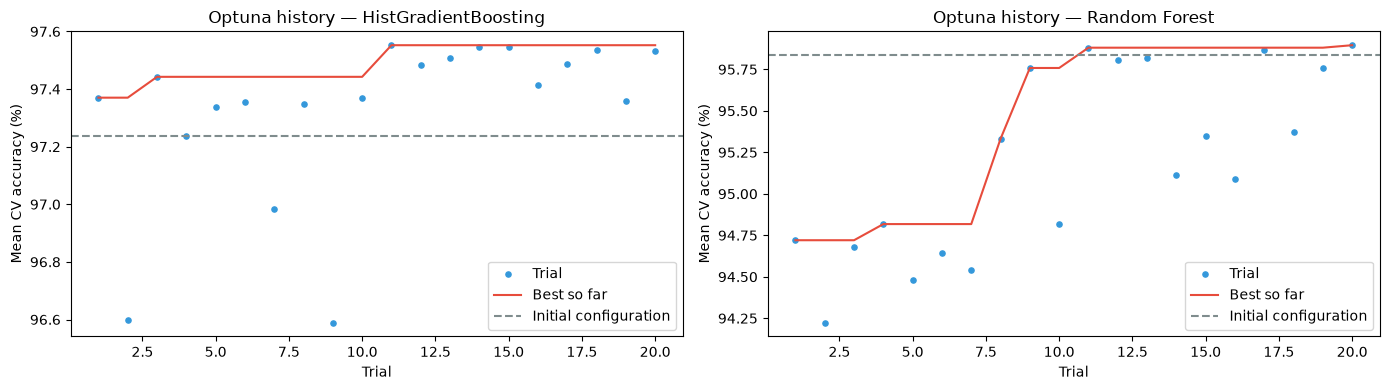

In [10]:
fig, axes = plt.subplots(1, len(studies), figsize=(7 * len(studies), 4), squeeze=False)
for ax, (name, s) in zip(axes[0], studies.items()):
    values = np.array([t.value for t in s.trials]) * 100
    ax.scatter(range(1, len(values) + 1), values, s=14, color="#3498DB", label="Trial")
    ax.plot(range(1, len(values) + 1), np.maximum.accumulate(values), color="#E74C3C", label="Best so far")
    initial_acc = initial.loc[initial["Model"] == name, "accuracy mean"].iloc[0] * 100
    ax.axhline(initial_acc, color="#7F8C8D", linestyle="--", label="Initial configuration")
    ax.set(title=f"Optuna history — {name}", xlabel="Trial", ylabel="Mean CV accuracy (%)")
    ax.legend(loc="lower right")
plt.tight_layout()
plt.show()

**Interpretation.** Each point is one trial (mean CV accuracy over the same five folds), the red line is the best value found so far and the dashed line is the initial configuration. The plots show how much of the search space improves on the defaults; the gain of the best trial is quantified with the identical protocol in §7.

# 7. Initial versus Tuned Models

The best trial is re-evaluated with the same `evaluate` function as the initial models, so both are measured with the identical protocol. Because the best trial was chosen *on these folds*, its score is optimistically biased; as a check, initial and tuned configurations are also compared on a second, independent grouped 5-fold split of the training partition (different shuffle seed). Test is not used.

In [11]:
CONFIRM_SPLITS = list(StratifiedGroupKFold(n_splits=N_SPLITS, shuffle=True, random_state=7)
                      .split(X_train, y_train, groups=groups_train))

tuned_estimators, comparison_rows = {}, []
for name, s in studies.items():
    tuned = suggest_estimator(name, optuna.trial.FixedTrial(s.best_params))
    tuned_estimators[name] = tuned
    for label, estimator in (("initial", CANDIDATES[name]), ("tuned", tuned)):
        main = evaluate(name, build_model_pipeline(estimator, pokemon, SELECTED_ARM), Version=label)
        confirm = evaluate(name, build_model_pipeline(estimator, pokemon, SELECTED_ARM), splits=CONFIRM_SPLITS)
        main["Confirmation accuracy mean"] = confirm["accuracy mean"]
        main["Confirmation accuracy std"] = confirm["accuracy std"]
        comparison_rows.append(main)

tuning_comparison = pd.DataFrame(comparison_rows)
tuning_comparison[["Model", "Version", "accuracy mean", "accuracy std", "roc_auc mean", "f1_macro mean",
                   "Confirmation accuracy mean", "Confirmation accuracy std", "Wall time (s)"]].round(4)

,Model,Version,accuracy mean,accuracy std,roc_auc mean,f1_macro mean,Confirmation accuracy mean,Confirmation accuracy std,Wall time (s)
0,HistGradientBoosting,initial,0.9724,0.0015,0.9963,0.9723,0.9729,0.0030,3.9825
1,HistGradientBoosting,tuned,0.9755,0.0013,0.9970,0.9754,0.9755,0.0034,15.1059
2,Random Forest,initial,0.9584,0.0024,0.9929,0.9583,0.9587,0.0015,16.1818
3,Random Forest,tuned,0.9590,0.0021,0.9927,0.9588,0.9584,0.0022,8.6506


**Interpretation.**
- **HistGradientBoosting:** tuning improves mean accuracy from 97.24% to 97.55% (+0.31 pp, about five times the standard error of the mean) with a slightly lower fold std (0.13 vs 0.15). On the independent confirmation split the gain is similar (97.29% → 97.55%), so it is not only an artifact of selecting the best trial on the main folds. The improvement is modest but consistent.
- **Random Forest:** 95.84% → 95.90% on the main folds and 95.87% → 95.84% on the confirmation split: no relevant improvement. The tuned version is cheaper (8.7 s vs 16.2 s) because it uses fewer trees.
- The tuned HistGradientBoosting costs more than its initial version (15.1 s vs 4.0 s per cross-validation), still small for this dataset.

# 8. Selection, Final Fit and Single Test Evaluation

### 8.1 Selection on cross-validation only (decision rule 3)

In [12]:
pool = pd.concat([
    initial[initial["Model"].isin(CANDIDATES)].assign(Version="initial"),
    tuning_comparison[tuning_comparison["Version"] == "tuned"],
], ignore_index=True)
pool["Label"] = pool["Model"] + " (" + pool["Version"] + ")"

leader = pool.loc[pool["accuracy mean"].idxmax()]
selection_se = leader["accuracy std"] / np.sqrt(N_SPLITS)
pool["Within 1 SE of best"] = pool["accuracy mean"] >= leader["accuracy mean"] - selection_se
selected = pool[pool["Within 1 SE of best"]].sort_values("Wall time (s)").iloc[0]

SELECTED_LABEL = selected["Label"]
SELECTED_ESTIMATOR = (tuned_estimators[selected["Model"]] if selected["Version"] == "tuned"
                      else CANDIDATES[selected["Model"]])

display(pool[["Label", "accuracy mean", "accuracy std", "roc_auc mean", "Wall time (s)", "Within 1 SE of best"]]
        .sort_values("accuracy mean", ascending=False).round(4))
print(f"Best mean accuracy: {leader['Label']} ({leader['accuracy mean']:.4f}); one standard error = {selection_se:.4f}")
print(f"Selected pipeline: {SELECTED_LABEL} on arm {SELECTED_ARM}")
print(f"Selected vs speed rule, per fold (pp): {np.round((selected['Fold accuracy'] - rule_fold_accuracy) * 100, 2)}")

,Label,accuracy mean,accuracy std,roc_auc mean,Wall time (s),Within 1 SE of best
4,HistGradientBoosting (tuned),0.9755,0.0013,0.9970,15.1059,True
3,HistGradientBoosting (initial),0.9724,0.0015,0.9963,4.2783,False
5,Random Forest (tuned),0.9590,0.0021,0.9927,8.6506,False
2,Random Forest (initial),0.9584,0.0024,0.9929,15.9861,False
0,Logistic Regression (initial),0.8866,0.0038,0.9336,1.1946,False
1,KNN (initial),0.8839,0.0027,0.9523,4.5179,False


Best mean accuracy: HistGradientBoosting (tuned) (0.9755); one standard error = 0.0006
Selected pipeline: HistGradientBoosting (tuned) on arm full
Selected vs speed rule, per fold (pp): [3.26 3.42 3.52 3.52 3.42]


**Interpretation.** The tuned HistGradientBoosting is the only configuration within one standard error (0.06 pp) of the best mean accuracy, so decision rule 3 selects it without a cost trade-off. It beats the speed rule in every fold by 3.26–3.52 pp. The next best configuration, the initial HistGradientBoosting, is 0.31 pp lower; Random Forest is about 1.6 pp lower.

### 8.2 Final fit on the whole training partition and single evaluation on test

The selected pipeline is refitted on all 40,078 training battles and evaluated **once** on the 9,922 holdout battles. The speed rule is scored on the same holdout as the reference benchmark. Nothing below is used to change any decision. For transparency: the preliminary run with a larger tuning budget (§6) also produced one holdout evaluation; it did not influence any choice in this notebook.

,Accuracy,Macro F1,ROC AUC
HistGradientBoosting (tuned) [full],0.9754,0.9753,0.9973
Speed rule (baseline),0.9376,0.9375,NaN


                 precision    recall  f1-score   support

Second wins (0)     0.9770    0.9763    0.9766      5226
 First wins (1)     0.9736    0.9744    0.9740      4696

       accuracy                         0.9754      9922
      macro avg     0.9753    0.9754    0.9753      9922
   weighted avg     0.9754    0.9754    0.9754      9922



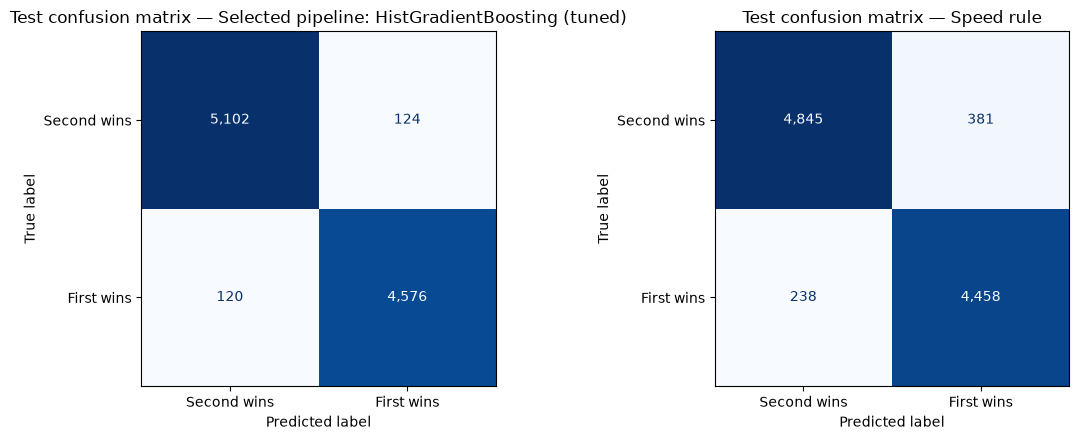

In [13]:
final_pipeline = build_model_pipeline(SELECTED_ESTIMATOR, pokemon, SELECTED_ARM).fit(X_train, y_train)
test_pred = final_pipeline.predict(X_test)
test_proba = final_pipeline.predict_proba(X_test)[:, 1]

test_features = create_pokemon_features(X_test, catalog=pokemon)
test_rule_pred = speed_rule_predict(test_features)

test_results = pd.DataFrame({
    "Accuracy": [accuracy_score(y_test, test_pred), accuracy_score(y_test, test_rule_pred)],
    "Macro F1": [f1_score(y_test, test_pred, average="macro"), f1_score(y_test, test_rule_pred, average="macro")],
    "ROC AUC": [roc_auc_score(y_test, test_proba), np.nan],
}, index=[f"{SELECTED_LABEL} [{SELECTED_ARM}]", "Speed rule (baseline)"])
display(test_results.round(4))
print(classification_report(y_test, test_pred, target_names=["Second wins (0)", "First wins (1)"], digits=4))

fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))
for ax, pred, title in ((axes[0], test_pred, f"Selected pipeline: {SELECTED_LABEL}"), (axes[1], test_rule_pred, "Speed rule")):
    ConfusionMatrixDisplay.from_predictions(y_test, pred, display_labels=["Second wins", "First wins"],
                                            cmap="Blues", values_format=",", ax=ax, colorbar=False)
    ax.set_title(f"Test confusion matrix — {title}")
plt.tight_layout()
plt.show()

**Interpretation.** On the 9,922 holdout battles the selected pipeline reaches **97.54% accuracy** (macro F1 97.53%, ROC AUC 0.9973), almost identical to its cross-validated 97.55%, so the CV estimate transferred to unseen matchups. The speed rule scores 93.76% on the same holdout. Errors are balanced between classes: recall is 97.63% when Second wins and 97.44% when First wins, with precision 97.70% and 97.36%, so the model does not favour one position.

# 9. Error Analysis, Limitations and Conclusions

### 9.1 Where does the final model fail?

The test errors are broken down by the segments that the EDA identified as decisive: the speed difference band, exact speed ties, and the special-form advantage. This is descriptive; it does not change the selected pipeline.

In [14]:
speed_gap = (test_features["Speed_first"] - test_features["Speed_second"]).abs()
segments = {
    "|ΔSpeed| band": pd.cut(speed_gap, bins=[-0.5, 0.5, 5, 10, 20, np.inf], labels=["0 (tie)", "1-5", "6-10", "11-20", ">20"]),
    "Special_Form_Advantage": test_features["Special_Form_Advantage"],
}
model_ok = pd.Series(test_pred == y_test.to_numpy(), index=X_test.index)
rule_ok = pd.Series(test_rule_pred == y_test.to_numpy(), index=X_test.index)

for title, segment in segments.items():
    table = pd.DataFrame({
        "Battles": segment.value_counts().sort_index(),
        "Model accuracy (%)": model_ok.groupby(segment, observed=False).mean() * 100,
        "Speed rule accuracy (%)": rule_ok.groupby(segment, observed=False).mean() * 100,
        "Model errors": (~model_ok).groupby(segment, observed=False).sum(),
    })
    table["Share of model errors (%)"] = table["Model errors"] / table["Model errors"].sum() * 100
    display(table.round(2).rename_axis(title))

print(f"Rule errors corrected by the model: {int((~rule_ok & model_ok).sum())} | "
      f"new errors introduced by the model: {int((rule_ok & ~model_ok).sum())} | "
      f"errors shared by both: {int((~rule_ok & ~model_ok).sum())}")

,Battles,Model accuracy (%),Speed rule accuracy (%),Model errors,Share of model errors (%)
|ΔSpeed| band,,,,,
0 (tie),278,99.28,100.00,2,0.82
1-5,894,99.78,97.54,2,0.82
6-10,938,99.47,97.65,5,2.05
11-20,1748,98.05,95.31,34,13.93
>20,6064,96.69,91.87,201,82.38


,Battles,Model accuracy (%),Speed rule accuracy (%),Model errors,Share of model errors (%)
Special_Form_Advantage,,,,,
-1,1216,97.78,95.89,27,11.07
0,7455,97.36,93.17,197,80.74
1,1251,98.40,95.20,20,8.20


Rule errors corrected by the model: 419 | new errors introduced by the model: 44 | errors shared by both: 200


**Interpretation.**
- **Where the errors are:** 201 of the model's 244 errors (82.4%) occur when the speed gap exceeds 20 points, the same band that concentrated the speed rule's errors in the EDA. These are battles the faster fighter loses; the model explains part of them (96.69% vs 91.87% for the rule) but not all.
- **Near speed parity the model is very accurate:** 99.47–99.78% for gaps of 1–10 points. On exact ties it is slightly worse than the rule (99.28% vs 100%, 2 errors in 278 battles): it has not fully learned that Second always wins ties.
- **Special forms:** accuracy is 97.36–98.40% across the three values of `Special_Form_Advantage`; most errors (80.7%) are in battles without a special-form advantage, which are also 75% of the holdout.
- **Compared with the rule:** the model corrects 419 of the rule's errors and introduces 44 new ones; 200 errors are shared by both.

### 9.2 Conclusions

| Question | Answer (cross-validation unless stated) |
|---|---|
| **Which pipeline was selected?** | `HistGradientBoostingClassifier` tuned with Optuna, on the `full` arm: raw stats, the five engineered features, one-hot types (types below 1% of training battles grouped) and `Legendary`, all inside `build_model_pipeline`. |
| **Mean performance and variation** | 97.55% ± 0.13 accuracy over five grouped folds (ROC AUC 0.997), 97.55% on the independent confirmation split, and 97.54% on the single holdout evaluation. |
| **Did tuning help?** | Yes for HistGradientBoosting: +0.31 pp on the main folds and +0.26 pp on the confirmation split, with a lower fold std. Modest but consistent. No relevant gain for Random Forest. |
| **Why this pipeline over similar ones?** | It is the only configuration within one standard error of the best mean, it beats the speed rule in all five folds, and the near-equivalent `full_onehot` arm adds columns without a measurable gain. Random Forest is about 1.6 pp lower; linear and distance-based models stay below the speed rule. |
| **What limitations remain?** | See below. |

**Limitations**
- **Test independence:** the EDA explored all 50,000 battles, and a preliminary run of this notebook with a larger tuning budget evaluated the holdout once. Neither was used for decisions, but the holdout is not a fully untouched external sample.
- **Scope:** the evaluation measures *Scenario A* (new matchups between known species). It does not measure generalization to unseen species; 16 species of the unlabelled `tests.csv` never appear in `combats.csv`.
- **Remaining errors:** most errors are battles where a much faster fighter loses. Moves, abilities and items are not in the data, so part of these outcomes may not be predictable from base stats and types.
- **Tuning:** 20 trials per model on spaces narrowed for cost; the best trial was chosen on the same folds that report it (mitigated by the confirmation split). Probability calibration was not assessed.
- **Attribution:** the gain of the `full` arm comes from types and `Legendary` together; their separate contributions, and whether `Special_Form_Advantage` adds signal beyond `Stat_Total_Diff`, were not isolated.

The test result describes the generalization of the chosen pipeline; it was not used to revisit any decision.